In [1]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.datasets import mnist

I0000 00:00:1792228244.891771   11353 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792228244.896601   11353 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1792228245.383661   11353 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1792228253.337754   11353 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.

In [2]:
plt.style.use("dark_background")
plt.rcParams.update({
    "font.size": 18,
    "axes.titlesize": 18,
    "axes.labelsize": 14,
    "xtick.labelsize": 14,
    "ytick.labelsize": 14,
    "legend.fontsize": 13,
    "figure.titlesize": 18,
})

In [3]:
RANDOM_STATE = 42

K_VALUES = [1, 3, 5, 7, 9, 15, 25, 35, 45, 55, 65, 75, 85, 95, 105]

ODIN_THRESHOLD = {k:10 for k in K_VALUES}

# 10% всей выборки = выбросы
OUTLIERS_P = 0.1
NOISE_SIGMA = 1

LABEL_CHANGE = "Изменённая метка"
STRONG_NOISE = "Равномерный шум"
HORIZONTAL_FLIP = "Отражённое"
BLACK_IMAGE = "Чёрное изображение"
WHITE_IMAGE = "Белое изображение"
ANOMALY_TYPES = [LABEL_CHANGE, STRONG_NOISE, HORIZONTAL_FLIP, BLACK_IMAGE, WHITE_IMAGE]


In [4]:
from sklearn.model_selection import train_test_split

(_, _), (X_MNIST_TEST, Y_MNIST_TEST) = mnist.load_data()

_, X, _, y = train_test_split(X_MNIST_TEST, Y_MNIST_TEST, test_size=0.1, random_state=RANDOM_STATE, stratify=Y_MNIST_TEST)

print(len(X), len(y))

1000 1000


In [5]:
OUTLIERS_N = len(X) * OUTLIERS_P
print(OUTLIERS_N)

100.0


In [6]:
def generate_outliers():
    rng = np.random.default_rng(RANDOM_STATE)
    n = len(X)
    n_outliers = int(round(n * OUTLIERS_P))

    # Используем одни и те же индексы во всех четырёх вариантах
    indices = rng.choice(n, size=n_outliers, replace=False)

    # 1. Изменение меток классов
    X_label = X.copy()
    y_label = y.copy()
    classes = np.unique(y)

    for i in indices:
        other_classes = classes[classes != y_label[i]]
        y_label[i] = rng.choice(other_classes)

    # 2. Сильный гауссовский шум
    X_noise = X.copy()
    low, high = 0.0, 255.0
    scale = max(high - low, 1.0)
    noisy_images = (
        X_noise[indices].astype(np.float32) + rng.normal(
            loc=0,
            scale=NOISE_SIGMA * scale,
            size=X_noise[indices].shape
        )
    )
    X_noise[indices] = np.clip(noisy_images, low, high).astype(X.dtype)
    y_noise = y.copy()

    # 3. Отражение изображений слева направо
    X_flip = X.copy()
    X_flip[indices] = X_flip[indices, :, ::-1]
    y_flip = y.copy()

    # 4. Полностью чёрные изображения
    X_black = X.copy()
    X_black[indices] = 0
    y_black = y.copy()

    # 5. Полностью белые изображения
    X_white = X.copy()
    X_white[indices] = 255
    y_white = y.copy()

    return {
        "indices": indices,
        "images": {
            LABEL_CHANGE: (X_label, y_label),
            STRONG_NOISE: (X_noise, y_noise),
            HORIZONTAL_FLIP: (X_flip, y_flip),
            BLACK_IMAGE: (X_black, y_black),
            WHITE_IMAGE: (X_white, y_white)
        }
    }

In [7]:
outliers_data = generate_outliers()


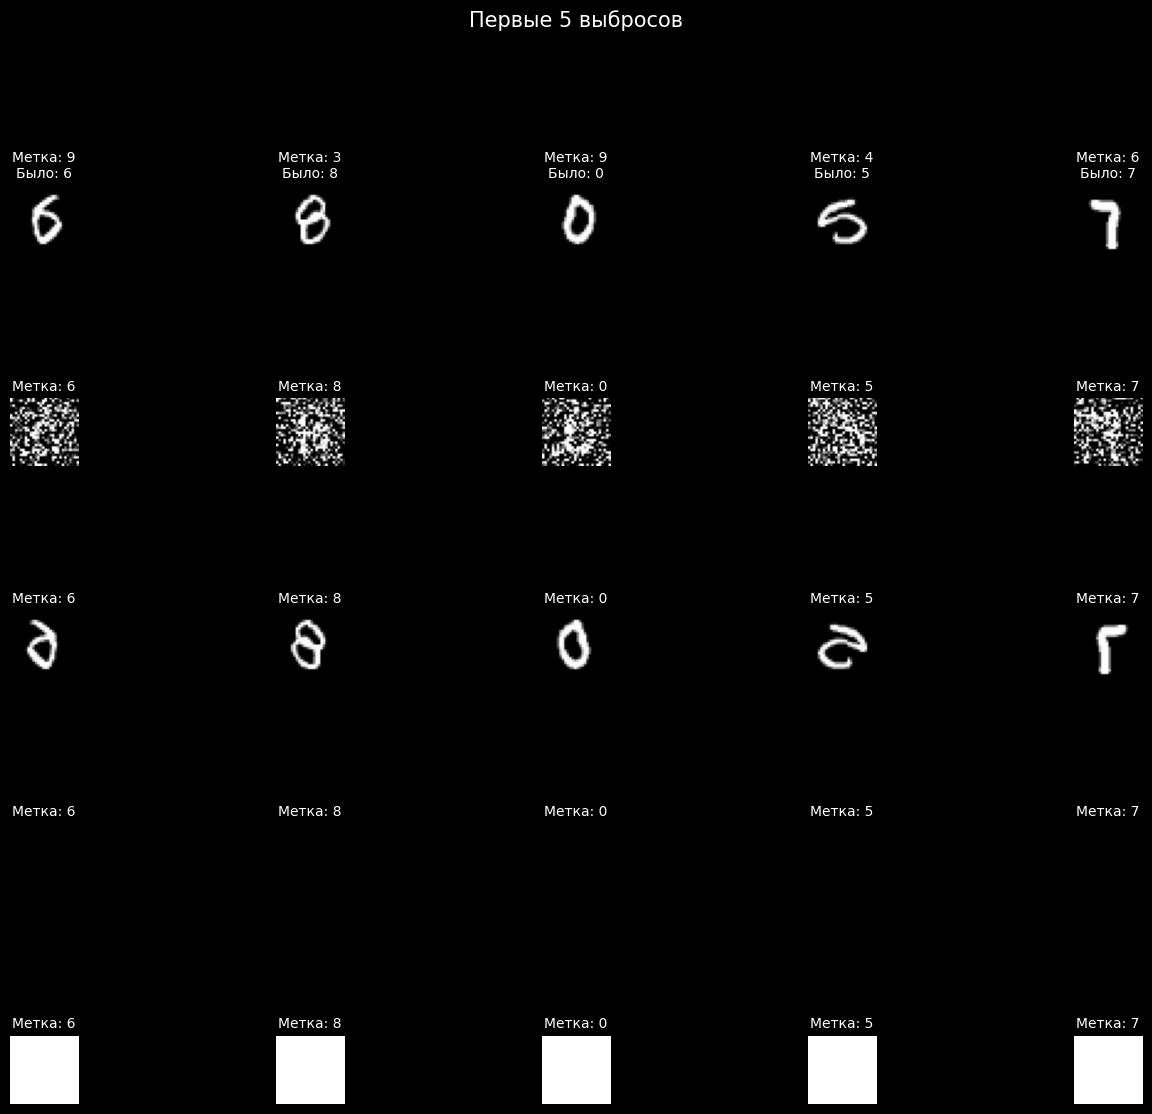

In [8]:
fig, axes = plt.subplots(
    nrows=len(ANOMALY_TYPES),
    ncols=5,
    figsize=(14, 11)
)

# Первые 5 выбросов
indices_to_show = outliers_data["indices"][:5]

for row, anomaly_type in enumerate(ANOMALY_TYPES):
    X_out, y_out = outliers_data["images"][anomaly_type]

    for col, idx in enumerate(indices_to_show):
        ax = axes[row, col]

        ax.imshow(X_out[idx], cmap="gray", vmin=0, vmax=255)
        ax.axis("off")

        # Для изменённой метки показываем исходную и новую метки
        if anomaly_type == LABEL_CHANGE:
            ax.set_title(
                f"Метка: {y_out[idx]}\nБыло: {y[idx]}",
                fontsize=10
            )
        else:
            ax.set_title(
                f"Метка: {y_out[idx]}",
                fontsize=10
            )

        # Название типа выброса у первого изображения строки
        if col == 0:
            ax.set_ylabel(
                anomaly_type,
                fontsize=11,
                rotation=90,
                labelpad=12
            )

fig.suptitle(
    "Первые 5 выбросов",
    fontsize=15,
    y=1.02
)

plt.tight_layout(rect=(0, 0, 1, 0.96), h_pad=5.0, w_pad=1.0)
plt.show()

In [9]:
from sklearn.metrics import pairwise_distances, f1_score

outliers_true = np.zeros(len(X), dtype=np.int8)
outliers_true[outliers_data["indices"]] = 1

# ...[type][k] - сколько выбросов типа type распознал метод k (f1)
knn_detected_data = {}
odin_detected_data = {}

for anomaly_type in ANOMALY_TYPES:
    knn_detected_data[anomaly_type] = {}
    odin_detected_data[anomaly_type] = {}
    X_current, y_current = outliers_data["images"][anomaly_type]
    X_current_flat = X_current.reshape(len(X_current), -1).astype(np.float32)

    # D[i, j] — евклидово расстояние между объектами i и j
    D = pairwise_distances(X_current_flat, metric="euclidean")

    # Исключаем каждый объект из поиска его ближайших соседей
    D_no_self = D.copy()
    np.fill_diagonal(D_no_self, np.inf)

    for k in K_VALUES:
        # Индексы k ближайших соседей каждого объекта без самого объекта
        neighbors_indices = np.argpartition(D_no_self,kth=k - 1,axis=1)[:, :k]

        # 1. KNN
        neighbors_labels = y_current[neighbors_indices]
        knn_y_pred = np.array([
            np.bincount(labels.astype(int)).argmax()
            for labels in neighbors_labels
        ])
        knn_pred = (knn_y_pred != y_current).astype(int)

        # 2. ODIN
        counts = np.bincount(neighbors_indices.ravel(),minlength=len(X_current))
        odin_pred = (counts < ODIN_THRESHOLD[k]).astype(int)

        knn_score = f1_score(outliers_true, knn_pred)
        odin_score = f1_score(outliers_true, odin_pred)

        # knn_score = np.sum(outliers_true == knn_pred).astype(int) / len(X)
        # odin_score = np.sum(outliers_true == knn_pred).astype(int) / len(X)

        knn_detected_data[anomaly_type][k] = knn_score
        odin_detected_data[anomaly_type][k] = odin_score

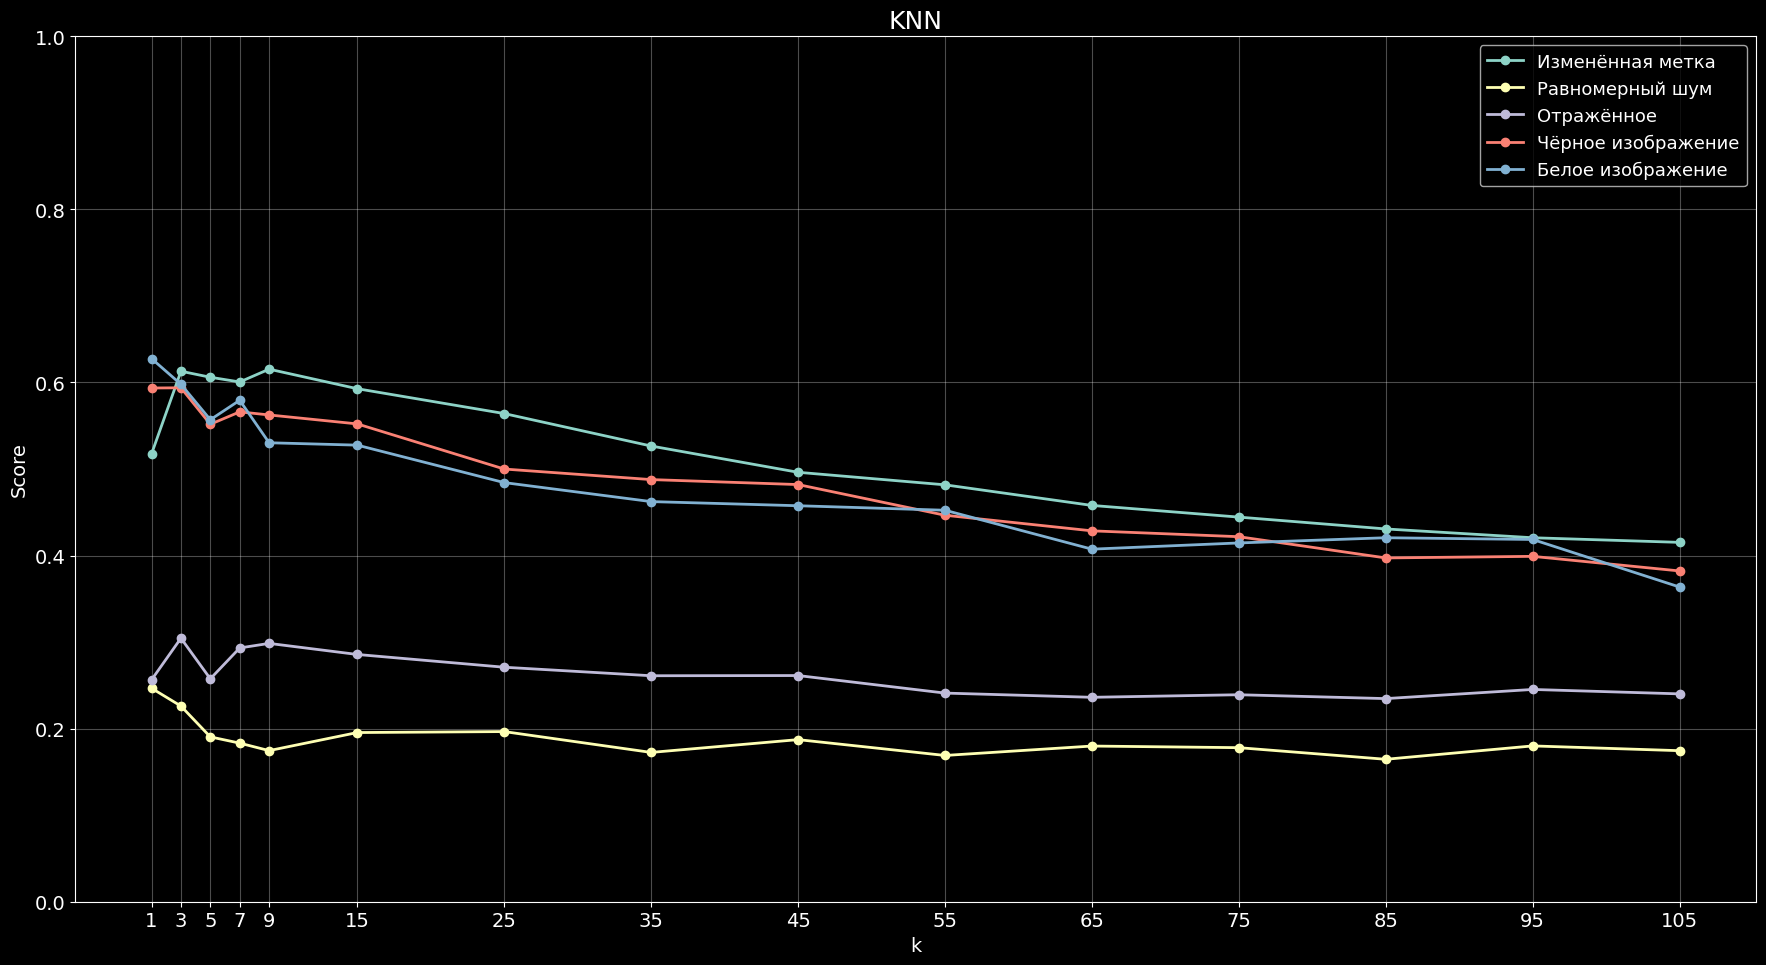

In [10]:
plt.figure(figsize=(18, 10))

for anomaly_type in ANOMALY_TYPES:
    y_plot = [
        knn_detected_data[anomaly_type][k]
        for k in K_VALUES
    ]

    plt.plot(
        K_VALUES,
        y_plot,
        marker="o",
        linewidth=2,
        label=anomaly_type
    )

plt.title("KNN")
plt.xlabel("k")
plt.ylabel("Score")
plt.xticks(K_VALUES)

plt.ylim(0, 1)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

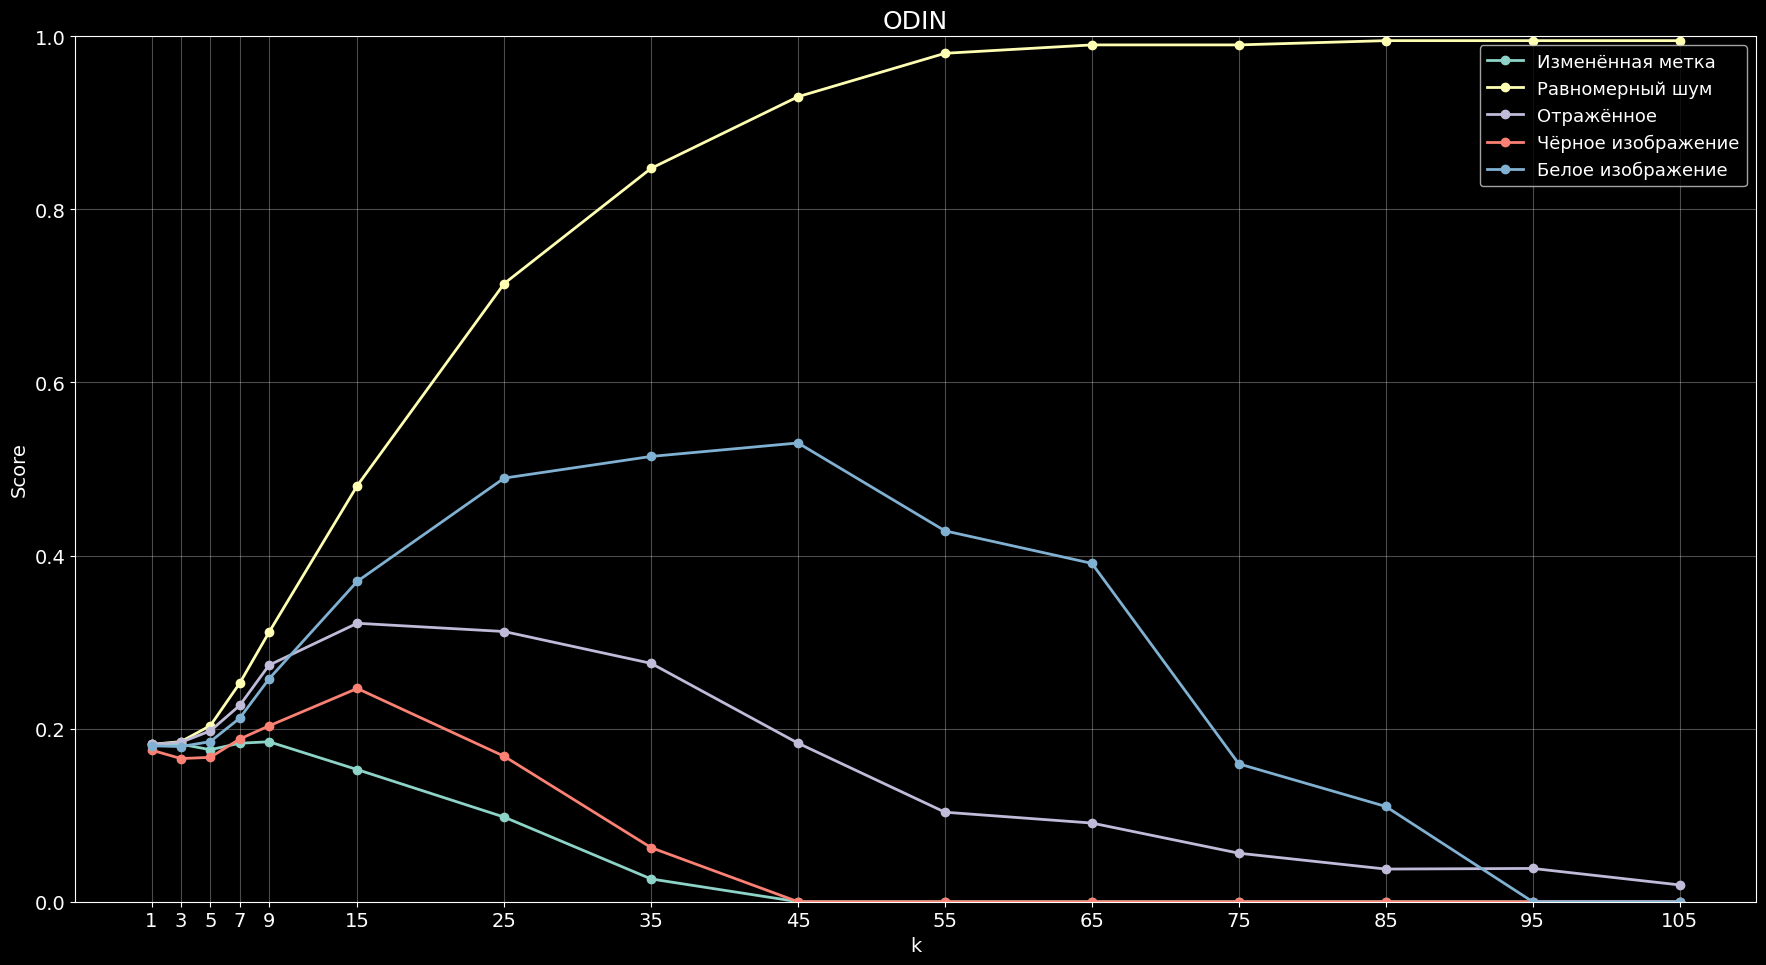

In [11]:
plt.figure(figsize=(18, 10))

for anomaly_type in ANOMALY_TYPES:
    y_plot = [
        odin_detected_data[anomaly_type][k]
        for k in K_VALUES
    ]

    plt.plot(
        K_VALUES,
        y_plot,
        marker="o",
        linewidth=2,
        label=anomaly_type
    )

plt.title("ODIN")
plt.xlabel("k")
plt.ylabel("Score")
plt.xticks(K_VALUES)

plt.ylim(0, 1)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

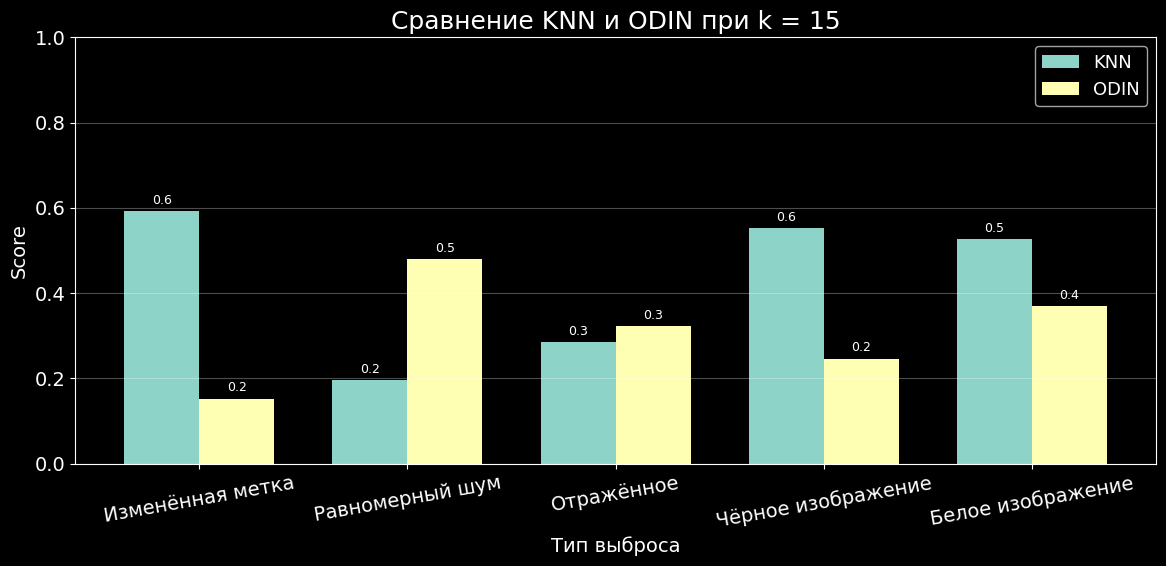

In [12]:
K_TO_COMPARE = 15

x = np.arange(len(ANOMALY_TYPES))
width = 0.36

knn_y = [
    knn_detected_data[t][K_TO_COMPARE]
    for t in ANOMALY_TYPES
]

odin_y = [
    odin_detected_data[t][K_TO_COMPARE]
    for t in ANOMALY_TYPES
]

fig, ax = plt.subplots(figsize=(12, 6))

bars_knn = ax.bar(
    x - width / 2,
    knn_y,
    width,
    label="KNN"
)

bars_odin = ax.bar(
    x + width / 2,
    odin_y,
    width,
    label="ODIN"
)

# Подписи процентов над столбцами
for bars in (bars_knn, bars_odin):
    for bar in bars:
        height = bar.get_height()

        ax.annotate(
            f"{height:.1f}",
            xy=(bar.get_x() + bar.get_width() / 2, height),
            xytext=(0, 3),
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontsize=9
        )

ax.set_xlabel("Тип выброса")
ax.set_ylabel("Score")
ax.set_title(f"Сравнение KNN и ODIN при k = {K_TO_COMPARE}")

ax.set_xticks(x)
ax.set_xticklabels(ANOMALY_TYPES, rotation=10)
ax.set_ylim(0, 1)

ax.legend()
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()